In [62]:
import numpy as np
from math import pi
import pyvista as pv
import matplotlib.pyplot as plt

def cart2pol(x, y):
    rho = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y, x)
    return(rho, phi)

# General Parameters
c_water = 1480
c_resin = 2636 

# Define Source Parameters
f = 2000e3
wavelength = c_water/f
print('Wavelength [mm] = ', wavelength * 1e3)
k = 2*pi*f/c_water

diameter = 25e-3
aperature = 15e-3

# Computational ("Domain") Parameters
domain_width = diameter
ppw = 2**4 # points per wavelength 2**4 recommended limit

dx = 2*pi/k/ppw # spatial step
Nx = int(domain_width/dx) # number of points in radial direction
Ny = Nx # number of points in angular direction

# Radial grid
r = np.linspace(0, domain_width/2, Nx)
theta = np.linspace(0, 2*pi, Ny)
R, Theta = np.meshgrid(r, theta)
X = R * np.cos(Theta)
Y = R * np.sin(Theta)

# Example Source
P0 = np.ones((Ny, Nx))
P0[R > aperature/2] = 0

# Add Focus
focal_z = 15*1e-3
focal_x = 0
focal_y = 0
focal_point = np.round([focal_x, focal_y, focal_z], 3) * 1e3
r = np.sqrt((X - focal_x)**2 + (Y - focal_y)**2 + focal_z**2)
P0 = P0 * np.exp(1j * k * r)
# Set phase to 0 for r > aperture
P0[R > aperature/2] = 0

# Add Vortex Phase
m = 0 # topological charge
P0 = P0 * np.exp(1j * Theta * m)

Wavelength [mm] =  0.74


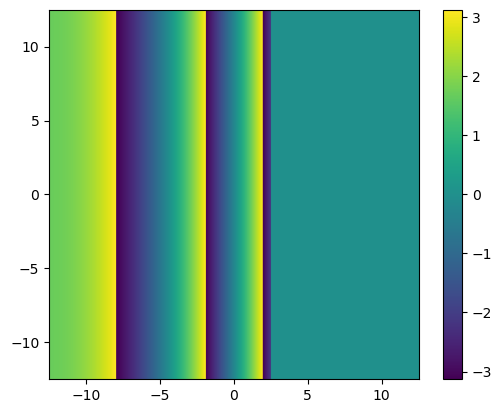

In [63]:
plt.imshow(np.angle(P0), extent=[-domain_width/2*1e3, domain_width/2*1e3, -domain_width/2*1e3, domain_width/2*1e3])
plt.colorbar()

0.0


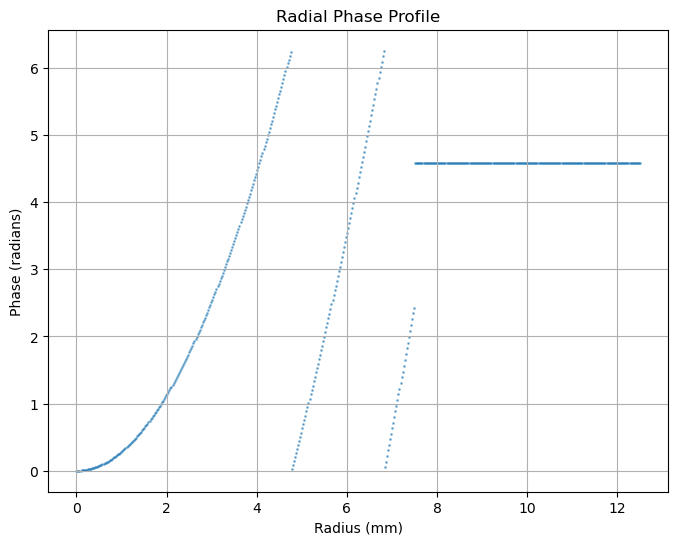

In [64]:

#### Generate Lens Profile ####

def delH(delPhase, c1, c2, f0):
    # ∆φ(x, y) = (k − k )∆T(x, y) Equation 8 kai melde Holograms for acoustics
    k1 = 2 * np.pi * f0 / c1
    k2 = 2 * np.pi * f0 / c2
    return delPhase / (k2 - k1)

# Unwrap the phase to remove discontinuities
P0_phase = np.unwrap(np.angle(P0), axis=1) 
P0_phase -= np.min(P0_phase)
print(np.min(P0_phase))
P0_phase = np.mod(P0_phase,2*pi)

# Plot the radial phase
# Plot the radial phase profile similar to the thickness radial plot
radial_r = R[int(Ny/2), :] * 1e3  # radius in mm
radial_phase = P0_phase[int(Ny/2), :]


plt.figure(figsize=(8, 6))
plt.scatter(radial_r, radial_phase, s=1, alpha=0.5)
plt.title('Radial Phase Profile')
plt.xlabel('Radius (mm)')
plt.ylabel('Phase (radians)')
plt.grid(True)
plt.show()


thickness = delH(P0_phase, c_resin, c_water, f)

Quarter Wavelength [mm] =  0.185


/opt/anaconda3/lib/python3.13/site-packages/pyvista/jupyter/notebook.py:56: UserWarning: Failed to use notebook backend: 

No module named 'trame'

Falling back to a static output.
  warnings.warn(


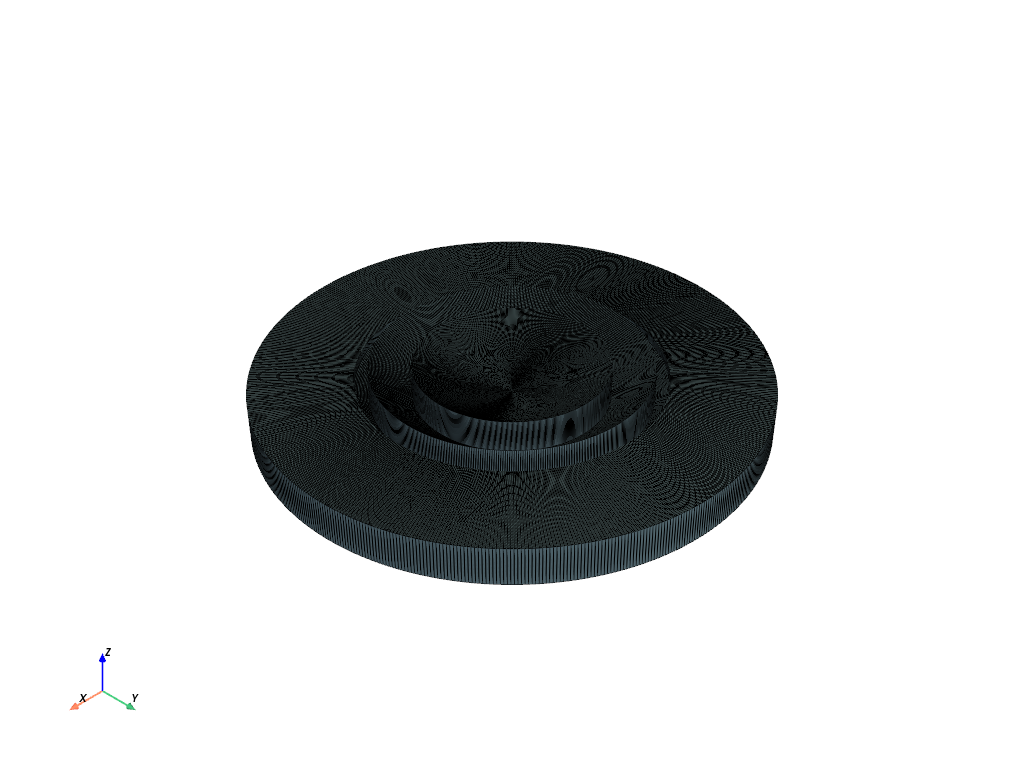

In [ ]:


##### create lens model from thickness ####

thickness += 5/4 * wavelength # add a small thickness to avoid zero thickness
thickness[R > diameter / 2] = 0
thickness[R >= aperature / 2] = 2e-3
mask_source = np.ones_like(P0)
mask_source[R > diameter / 2] = 0


# Crop domain not part of the physical source
thickness_source = thickness[mask_source == 1]
R_source = R[mask_source == 1]
Theta_source = Theta[mask_source == 1]c
# Create new domain
Nx_source = np.sqrt(thickness_source.shape)[0].astype('int')
Ny_source = Nx_source

thickness_source = np.reshape(thickness_source, [Ny_source, Nx_source])
R_source = np.reshape(R_source, [Ny_source, Nx_source])
Theta_source = np.reshape(Theta_source, [Ny_source, Nx_source])

X_source = R_source * np.cos(Theta_source)
Y_source = R_source * np.sin(Theta_source)

struct = pv.StructuredGrid(X_source, Y_source, thickness_source)
# struct.plot(show_edges=True)

top = struct.points.copy()
bottom = struct.points.copy()
bottom[:, -1] = 0  # Wherever you want the plane 
print('Quarter Wavelength [mm] = ', wavelength * 1e3 / 4)

vol = pv.StructuredGrid()
vol.points = np.vstack((top, bottom))
vol.dimensions = [*struct.dimensions[0:2], 2]

# Remove points in vol with a radius in the xy plane greater than diameter/2
points = vol.points
radii = np.sqrt(points[:, 0]**2 + points[:, 1]**2)
mask = radii <= diameter / 2
vol = vol.extract_points(mask)

# Convert vol to a mesh
mesh = vol.extract_surface()

mesh.plot(show_edges=True)

# Save the mesh as an STL file
mesh.save('2MHz_focus_mm_Slimmed.stl')

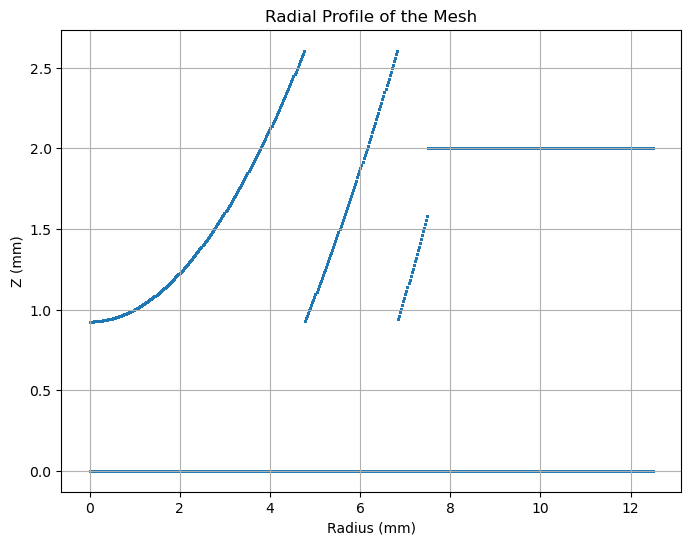

Wavelength in water [mm]: 0.74
Wavelength in resin [mm]: 1.3179999999999998


In [66]:

# Plot the radial profile of the mesh
radii = np.sqrt(mesh.points[:, 0]**2 + mesh.points[:, 1]**2)
z_values = mesh.points[:, 2]

plt.figure(figsize=(8, 6))
plt.scatter(radii*1e3, z_values*1e3, s=1, alpha=0.5)
plt.title('Radial Profile of the Mesh')
plt.xlabel('Radius (mm)')
plt.ylabel('Z (mm)')
plt.grid(True)
plt.show()

# Print wavelengths in both media
print(f"Wavelength in water [mm]: {wavelength * 1e3}")
wavelength_resin = c_resin / f
print(f"Wavelength in resin [mm]: {wavelength_resin * 1e3}")


In [ ]:
print(z_values.max()*1e3)


2.605292371494916


: 